# Importing Libraries

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import xgboost as xgb

# Loading data....

In [13]:
df = pd.read_csv(r"C:\Users\Lenovo\Downloads\retail_Sales_data_clean.csv")
df.head()

,order_id,order_date,customer_id,customer_name,age,gender,region,city,product_category,product_name,...,unit_price,discount_pct,sales_amount,profit,shipping_cost,payment_method,customer_satisfaction,return_status,order_status,days_to_ship
0,ORD-03903,2024-08-15,CUST32603,Aarav Mehta,39,Other,Central,Raipur,Groceries,Sugar,...,346.32,0.00,4043.14,289.18,56.04,Debit Card,1,True,Returned,7
1,ORD-02198,2022-08-16,CUST07881,Sanjay Verma,28,Male,West,Mumbai,Beauty,Sunscreen,...,858.66,0.08,9147.31,5355.56,64.49,Debit Card,5,False,Delivered,2
2,ORD-01348,2021-08-29,CUST49296,Pooja Sharma,41,Other,West,Surat,Furniture,Sofa,...,25941.32,0.14,110156.97,36956.51,67.65,Debit Card,4,False,Delivered,5
3,ORD-02076,2022-07-05,CUST05587,Priya Reddy,29,Other,West,Ahmedabad,Furniture,Bed Frame,...,22071.92,0.17,262066.11,66644.99,54.47,EMI,3,False,Delivered,4
4,ORD-00287,2020-05-07,CUST58035,Ritu Sharma,35,Male,Central,Nagpur,Groceries,Cooking Oil,...,320.06,0.31,323.95,31.38,48.81,Net Banking,4,False,Pending,4


In [14]:
df.isnull().sum()

order_id                 0
order_date               0
customer_id              0
customer_name            0
age                      0
gender                   0
region                   0
city                     0
product_category         0
product_name             0
quantity                 0
unit_price               0
discount_pct             0
sales_amount             0
profit                   0
shipping_cost            0
payment_method           0
customer_satisfaction    0
return_status            0
order_status             0
days_to_ship             0
dtype: int64

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4120 entries, 0 to 4119
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               4120 non-null   object 
 1   order_date             4120 non-null   object 
 2   customer_id            4120 non-null   object 
 3   customer_name          4120 non-null   object 
 4   age                    4120 non-null   int64  
 5   gender                 4120 non-null   object 
 6   region                 4120 non-null   object 
 7   city                   4120 non-null   object 
 8   product_category       4120 non-null   object 
 9   product_name           4120 non-null   object 
 10  quantity               4120 non-null   int64  
 11  unit_price             4120 non-null   float64
 12  discount_pct           4120 non-null   float64
 13  sales_amount           4120 non-null   float64
 14  profit                 4120 non-null   float64
 15  ship

In [26]:
df.describe()

,age,quantity,unit_price,discount_pct,sales_amount,profit,shipping_cost,customer_satisfaction,days_to_ship,target_return
count,4120.000000,4120.000000,4120.000000,4120.000000,4120.000000,4120.000000,4120.000000,4120.000000,4120.000000,4120.000000
mean,35.108738,5.489806,10787.472934,0.195150,55897.016981,10887.054434,63.431898,3.126456,5.534951,0.145874
std,10.655128,2.856509,17496.312575,0.121394,113785.509312,27113.900369,18.263168,1.467386,2.809176,0.353022
min,13.000000,1.000000,51.210000,0.000000,42.950000,2.870000,0.510000,1.000000,1.000000,0.000000
25%,28.000000,3.000000,702.210000,0.090000,2476.405000,725.612500,50.875000,2.000000,3.000000,0.000000
50%,35.000000,5.000000,2259.075000,0.200000,9676.200000,3181.360000,63.455000,3.000000,6.000000,0.000000
75%,42.000000,8.000000,12914.815000,0.300000,50728.260000,10567.950000,75.692500,5.000000,8.000000,0.000000
max,72.000000,10.000000,79957.920000,0.400000,991905.810000,921794.600000,133.350000,5.000000,10.000000,1.000000


In [27]:
return_vs_not=df.groupby("return_status")["return_status"].size()
print(return_vs_not)

return_status
False    3519
True      601
Name: return_status, dtype: int64


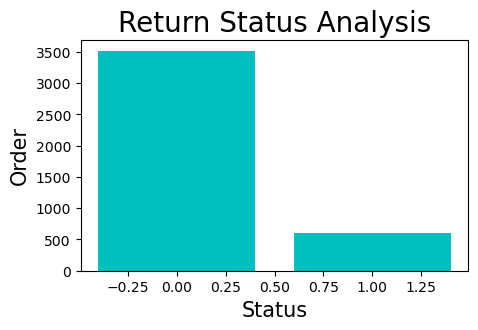

In [37]:
plt.figure(figsize=(5,3))
plt.bar(return_vs_not.index,return_vs_not.values,color='c')
plt.title("Return Status Analysis",fontsize=20)
plt.xlabel("Status",fontsize=15)
plt.ylabel("Order",fontsize=15)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

# Feature Engineering

In [16]:
df['target_return'] = df['return_status'].astype(int)

In [17]:
# Numeric Features
numeric_features = [
    'age','quantity','unit_price','discount_pct','shipping_cost','days_to_ship','customer_satisfaction']
# Categorial Features
categorical_features = ['gender', 'region', 'product_category', 'payment_method']

In [18]:
# One-Hot Encode the categorial features 
X = pd.get_dummies(df[numeric_features + categorical_features], drop_first=True)
y = df['target_return']

In [19]:
# Spliting the Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Initialize and train the XGBoost Model

In [20]:
# Initializing the XGBoost Model
xgb_model = xgb.XGBClassifier(
    n_estimators=150,       
    learning_rate=0.1,      
    max_depth=5,       
    random_state=42,
    eval_metric='logloss'
)

In [21]:
# Training the data
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

# Evalution Metrics

In [22]:
# Print out the Evalution metrics
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.86      0.99      0.92       704
           1       0.45      0.04      0.08       120

    accuracy                           0.85       824
   macro avg       0.66      0.52      0.50       824
weighted avg       0.80      0.85      0.80       824

=== Confusion Matrix ===
[[698   6]
 [115   5]]


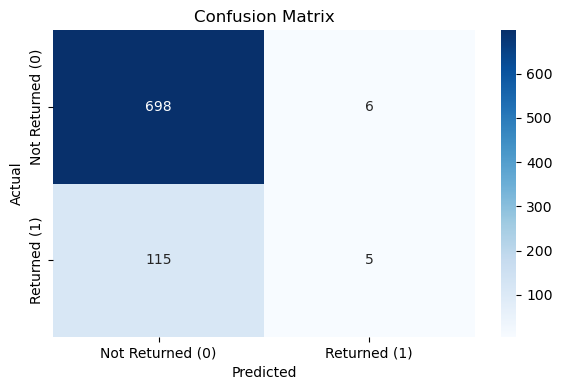

In [25]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
xticklabels=['Not Returned (0)', 'Returned (1)'], yticklabels=['Not Returned (0)', 'Returned (1)'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

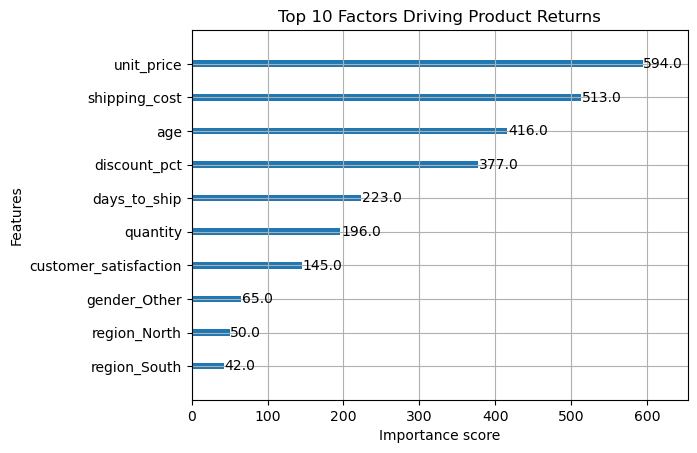

In [23]:
# Important Features
xgb.plot_importance(xgb_model, max_num_features=10, importance_type='weight')
plt.title("Top 10 Factors Driving Product Returns")
plt.show()